# Week 6: Natural experiments and midterm review
**DS-UA 201 · Fall 2026**  
**Center for Data Science, New York University**  

**TA: Xiang Gao**

Oct 16, 2026

[Open in Colab](https://colab.research.google.com/github/xgao0o/DS-UA_201-Causal-Inference-Fall-2026/blob/main/labs/6-Natural_Experiments.ipynb) (available after publication to the repository).

The Dutch Postcode Lottery file contains **real historical data**. All other datasets in this notebook are **synthetic teaching examples**, not empirical findings.

## Setup
Run cells from top to bottom, or choose **Restart Kernel and Run All Cells**. We use NumPy, pandas, Matplotlib, SciPy, and statsmodels. Simulations use separate fixed random seeds and need no downloads.

- **Locally:** keep `labs/6-Natural_Experiments.ipynb` and `data/FinalAnon.dta` in their repository folders. Start from either `labs/` or the repository root.
- **Colab:** upload the notebook and the accompanying `data/FinalAnon.dta` in the Files sidebar before running all cells. Uploads may need to be repeated in a new session.
- If needed, install with `python -m pip install numpy pandas matplotlib scipy statsmodels` (or `%pip install numpy pandas matplotlib scipy statsmodels` inside Colab).

In [1]:
%matplotlib inline

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from IPython.display import display

plt.rcParams.update({
    "figure.figsize": (7, 4), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE = "#526F8A", "#B85C38"

## 1. From experiments to observational data
An experiment lets researchers control the assignment mechanism. Sometimes an experiment is too costly, too slow, or infeasible. Observational data can still contain useful causal variation, but a large dataset alone does not create it.

A **natural experiment** uses an external event or institutional rule that assigns exposure plausibly **as if at random** for a specified population, perhaps within particular groups. “Natural” does not mean that the event must come from nature: a lottery run by an outside organization is one example.

Recall the all-causes model: $Y_i(s)=Y(s,U_i)$, where $U_i$ collects other causes of the outcome, observed or unobserved. For binary treatment $S_i$, the observed outcome is

$$Y_i=S_iY_i(1)+(1-S_i)Y_i(0).$$

To interpret an unadjusted outcome difference causally, we need:

1. **As-if random assignment:** $S\perp (Y(0),Y(1))$ in the target population. The course's $S\perp U$ is a sufficient condition in this model.
2. **Consistency and a well-defined exposure:** the recorded outcome corresponds to the exposure actually received. SUTVA also rules out relevant hidden treatment versions and interference between the analysis units.
3. **Both exposure states possible:** $0<P(S=1)<1$.

These conditions allow other variables to cause outcomes. They do not require treatment to be the only cause of $Y$.

### Parameter → identification → estimator → estimate
The population **average treatment effect** is $\tau=\mathbb E[Y(1)-Y(0)]$. Under the assumptions above,

$$\tau=\mathbb E[Y\mid S=1]-\mathbb E[Y\mid S=0].$$

This is **identification**: expressing a causal parameter using the observed-data distribution. We then estimate it with

$$\hat\tau=\bar Y_1-\bar Y_0,\qquad
\bar Y_s=\frac{1}{n_s}\sum_{i:S_i=s}Y_i.$$

The numerical result on one dataset is the **realized estimate**. A sample mean is not a population expectation. For binary $S$, OLS with an intercept and $S$ as the only predictor gives exactly this sample difference, whether or not the comparison is causal.

Random assignment also makes population $\operatorname{ATT}=\mathbb E[Y(1)-Y(0)\mid S=1]$ and $\operatorname{ATU}=\mathbb E[Y(1)-Y(0)\mid S=0]$ equal to the ATE. With heterogeneous effects, finite treated and untreated groups can still have different average effects by chance.

### Exercise 1: what was randomized?
A draft lottery randomizes eligibility $Z$, but some eligible people never serve and some ineligible people volunteer. Does comparing earnings by $Z$ directly identify the effect of military service $S$?

<details><summary>Answer</summary>

It identifies the effect of **eligibility/assignment** under the assignment-level assumptions: an intention-to-treat (ITT) effect. It does not automatically identify the effect of service received. Perfect compliance is not needed for the ITT; it is one way to make assignment equal treatment received. Recovering a service effect with noncompliance requires additional assumptions and methods covered later.

</details>

## 2. Random versus nonrandom assignment
Generate an observed pretreatment characteristic $U_i$ and noise $\varepsilon_i$, then define

$$Y_i(0)=U_i+\varepsilon_i,\qquad Y_i(1)=Y_i(0)+2.$$

The population ATE and every finite-group average effect are 2 in this constant-effect simulation. Compare independent random assignment with selection $S_i=1\{U_i>0\}$. Do not change potential outcomes after assigning treatment.

,Known effect,Observed difference,Baseline gap
Assignment,,,
Random,2,1.859,-0.141
Selected on U,2,3.569,1.569


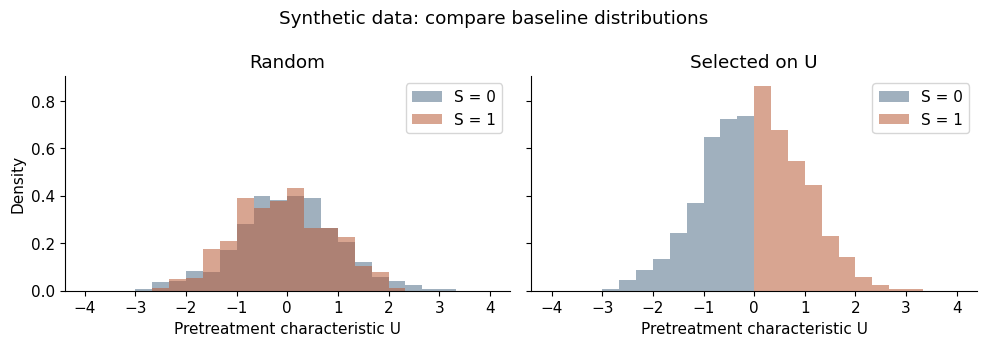

In [2]:
assignment_rng = np.random.default_rng(6201)
n = 1000
u = assignment_rng.normal(size=n)
noise = assignment_rng.normal(size=n)
y0 = u + noise
y1 = y0 + 2
assignment_rules = {
    "Random": assignment_rng.binomial(1, 0.5, n),
    "Selected on U": (u > 0).astype(int),
}
assignment_data, comparison_rows = {}, []
for name, s in assignment_rules.items():
    observed_y = np.where(s == 1, y1, y0)
    frame = pd.DataFrame({"U": u, "S": s, "Y": observed_y})
    assignment_data[name] = frame
    difference = frame.groupby("S")["Y"].mean().diff().iloc[-1]
    baseline_gap = y0[s == 1].mean() - y0[s == 0].mean()
    comparison_rows.append({
        "Assignment": name, "Known effect": 2,
        "Observed difference": difference, "Baseline gap": baseline_gap,
    })
    assert np.isclose(difference, 2 + baseline_gap)
display(pd.DataFrame(comparison_rows).set_index("Assignment").round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True, sharey=True)
bins = np.linspace(-4, 4, 25)
for ax, (name, frame) in zip(axes, assignment_data.items()):
    for s, color in [(0, BLUE), (1, ORANGE)]:
        ax.hist(frame.loc[frame.S == s, "U"], bins=bins, density=True,
                alpha=0.55, color=color, label=f"S = {s}")
    ax.set(title=name, xlabel="Pretreatment characteristic U")
    ax.legend()
axes[0].set_ylabel("Density")
fig.suptitle("Synthetic data: compare baseline distributions")
fig.tight_layout()
plt.show()

### Balance is a diagnostic, not a proof
**Covariate balance** concerns the distribution of pretreatment characteristics across treatment groups. Here we can inspect $U$; in a real study, many relevant causes are unmeasured. Under random assignment, population distributions coincide, but finite samples will not match exactly.

The **standardized mean difference (SMD)** below divides the treated-minus-control mean difference by the square root of the average of the two sample variances. It is a descriptive, unit-free measure of mean imbalance, not a test of full distributional equality. There is no universal pass/fail cutoff that proves a design valid.

In [3]:
balance_rows = []
for name, frame in assignment_data.items():
    u1 = frame.loc[frame.S == 1, "U"]
    u0 = frame.loc[frame.S == 0, "U"]
    gap = u1.mean() - u0.mean()
    scale = np.sqrt((u1.var(ddof=1) + u0.var(ddof=1)) / 2)
    balance_rows.append({"Assignment": name, "Mean U: S=0": u0.mean(),
                         "Mean U: S=1": u1.mean(), "SMD": gap / scale})
display(pd.DataFrame(balance_rows).set_index("Assignment").round(3))

,Mean U: S=0,Mean U: S=1,SMD
Assignment,,,
Random,0.011,-0.092,-0.107
Selected on U,-0.783,0.754,2.669


### Exercise 2: diagnosing a design
1. Why is the selected comparison above 2? Is its error just random imbalance?
2. If observed characteristics have similar means, have we established independence?
3. Can adjusting for $U$ by within-$U$ comparisons solve this particular selected design?

<details><summary>Answer</summary>

1. The selected treated group has systematically larger $U$ and therefore larger untreated outcomes. Its population outcome difference is $2+2\sqrt{2/\pi}$, about 3.60, because $U$ is standard normal. A single realized error is not itself repeated-sampling bias, but this assignment rule creates bias across repetitions.
2. No. Equal means need not imply equal distributions, and unobserved characteristics cannot be checked. Balance must be considered alongside the assignment mechanism, timing, selection into the dataset, and substantive knowledge. A nonsignificant balance test can also reflect low power; occasional significant tests occur under random assignment.
3. No nonparametric within-$U$ comparison is available: treatment is deterministic given $U$. There is no overlap. Any regression-based answer would rely on extrapolation or additional structure, not merely conditioning.

</details>

## 3. Dutch Postcode Lottery: define the question
In the historical Dutch Postcode Lottery studied by **Kuhn, Kooreman, Soetevent, and Kapteyn (2011)**, postcodes were selected by lottery and prizes went to **participating ticket holders** in those postcodes. Living in a winning postcode did not mean every resident received a prize. The study also examined effects on neighbors. [Published paper](https://www.aeaweb.org/articles?id=10.1257/aer.101.5.2226).

Separate three variables:

| Variable | Meaning | Design implication |
|---|---|---|
| $P_i$ | Participated before the draw | Chosen by households; participation is not randomized |
| $Z_g$ | Postcode $g$ selected to win | Source of random assignment |
| $R_i$ | Household received a prize | Depends on participation and the draw |

Among people who participated **before** the draw, comparing winning and nonwinning postcodes can target

$$\tau_{\mathrm{players}}=\mathbb E[Y_i(1)-Y_i(0)\mid P_i=1],$$

where $Y_i(z)$ is spending under postcode assignment $z$. This exposure may include both one's own prize and neighbors' prizes. It is not an isolated effect of receiving one euro. Comparing players to nonplayers would not use the lottery's randomization.

### SUTVA
At the individual level, a neighbor's prize can affect one's outcome: **interference**. Defining exposure at the postcode level allows effects within a postcode, but still requires a credible restriction on effects **across** postcodes. Clustering standard errors does not remove interference or confounding.


### Exercise 3: define the comparison
Would restricting the analysis to actual prize recipients provide a treated and a control group? Why should participation be measured before the draw?

<details><summary>Answer</summary>

Actual recipients are selected by the realized draw and provide no nonrecipient comparison within that subset. To study prior players, use a participation measure defined before assignment and retain players in both winning and nonwinning postcodes. Participation measured afterward could itself respond to winning, so conditioning on it could introduce selection bias.

</details>

## 4. Work with the historical data
We retain the regression, `durable_spending ~ win_code`, using its supplied `FinalAnon.dta`. This is a **simplified teaching analysis**, not a replication of a published table.

The supplied file includes both prize recipients and nonrecipients. Consequently, the unrestricted regression below describes a **pooled household comparison by postcode assignment**, not the player-only parameter just defined. Giving it a causal interpretation requires as-if random exposure in the analyzed population, adequate handling of the survey sampling/response process, and an appropriate interference assumption. We do not silently label this pooled estimate “the effect on winners.”

| Field | Use in this lab |
|---|---|
| `durable_spending` | Recorded durable-goods expenditure, in euros |
| `win_code` | Indicator for a winning postcode |
| `pstk` | Postcode identifier; clustering unit |
| `winner` | Recorded household winner indicator; used only to inspect sample composition |

Read the file as supplied; do not automatically turn zeros into missing values or infer a player-only sample from the winner indicator. Original survey coding and sample restrictions need to be checked before a more ambitious replication. The [replication archive](https://www.openicpsr.org/openicpsr/project/116096/version/V1/view) documents the research source; the local course copy is what we analyze here.

In [4]:
candidates = [Path("data/FinalAnon.dta"), Path("../data/FinalAnon.dta"),
              Path("FinalAnon.dta")]
data_path = next((p for p in candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError(
        "Upload FinalAnon.dta in Colab, or keep it in the repository's data/ folder."
    )
lotto = pd.read_stata(data_path, convert_categoricals=False)
required = ["durable_spending", "win_code", "pstk", "winner"]
display(lotto[required].head())
display(lotto[required].isna().sum().rename("Missing rows").to_frame())

# Drop model-missing rows BEFORE fitting, so cluster labels align with outcomes.
lotto_analysis = lotto.dropna(subset=required[:3]).copy()
lotto_analysis["durable_spending"] = lotto_analysis["durable_spending"].astype(float)
assert set(lotto_analysis.win_code.unique()) == {0, 1}
assert lotto_analysis.groupby("pstk").win_code.nunique().eq(1).all()
print(f"Loaded {len(lotto):,} households; analyzed {len(lotto_analysis):,}; "
      f"postcodes = {lotto_analysis.pstk.nunique():,}.")
display(pd.crosstab(lotto_analysis.win_code, lotto_analysis.winner,
                    rownames=["Winning postcode"], colnames=["Household winner"]))

,durable_spending,win_code,pstk,winner
0,0.0,0,512056,0
1,0.0,0,512056,0
2,0.0,1,512066,1
3,0.0,1,512066,1
4,0.0,1,512066,0


,Missing rows
durable_spending,0
win_code,0
pstk,0
winner,0


Loaded 1,879 households; analyzed 1,879; postcodes = 401.


Household winner,0,1
Winning postcode,,
0,1179,0
1,506,194


### Compare means and regression; then account for clusters
Households in the same postcode share assignment and may share shocks. Ordinary heteroskedasticity-robust standard errors (HC2) still treat households as independent. **Postcode-clustered standard errors** allow residual dependence within a postcode and rely on sufficiently many independent clusters for approximate inference.

We use a conventional finite-sample correction and a $t_{G-1}$ reference, where $G$ is the number of postcodes. This is an approximation, not a guarantee for every cluster design. The covariance choice changes uncertainty, not the OLS coefficient.

In [5]:
real_means = lotto_analysis.groupby("win_code").durable_spending.agg(["mean", "size"])
real_gap = real_means.loc[1, "mean"] - real_means.loc[0, "mean"]
real_model = smf.ols("durable_spending ~ win_code", data=lotto_analysis)
real_hc2 = real_model.fit(cov_type="HC2", use_t=False)
real_cluster = real_model.fit(
    cov_type="cluster",
    cov_kwds={"groups": lotto_analysis.pstk,
              "use_correction": True, "df_correction": True},
    use_t=True,
)
assert np.isclose(real_gap, real_cluster.params["win_code"])
display(real_means.round(2))
real_rows = []
for name, fit in [("HC2 (independent households)", real_hc2),
                  ("Clustered by postcode", real_cluster)]:
    lo, hi = fit.conf_int().loc["win_code"]
    real_rows.append({"Method": name, "Estimate (EUR)": fit.params["win_code"],
                      "SE (EUR)": fit.bse["win_code"],
                      "95% lower": lo, "95% upper": hi,
                      "p-value": fit.pvalues["win_code"]})
display(pd.DataFrame(real_rows).set_index("Method").round(3))

,mean,size
win_code,,
0,768.21,1179
1,887.24,700


,Estimate (EUR),SE (EUR),95% lower,95% upper,p-value
Method,,,,,
HC2 (independent households),119.023,183.158,-239.961,478.007,0.516
Clustered by postcode,119.023,180.316,-235.463,473.509,0.510


The supplied file gives a pooled difference of about **€119**: average recorded durable spending is higher in winning postcodes in this sample. Interpret the interval and p-value in the output before drawing conclusions. This number is not the player-only effect and need not match an estimate from lecture slides or a published table using another sample or specification.

### Exercise 4: write a defensible conclusion
Does the clustered interval exclude zero? Does that prove either “no effect” or “the lottery causes more spending”? Why would 1,879 household rows not mean 1,879 independent assignments?

<details><summary>Answer</summary>

The clustered interval here includes zero. The data and this simplified specification do not give a precise estimate that rules out zero at the conventional 5% level. This does not establish a zero effect, and the point estimate alone does not establish a positive causal effect. Identification depends on the design and sample, separately from uncertainty. Assignment is shared within each of the 401 postcodes, so the household rows are not independent assignment units.

</details>

## 5. A synthetic postcode lottery
Now isolate the mechanism in data where the truth is known. This **does not reproduce the historical study**. Imagine 60 postcodes, each with 20 households who all entered before the draw. Select **20 distinct postcodes** uniformly from the postcode list, not from a household-level list with repeated codes.

Construct potential spending before assignment:

$$Y_{ig}(0)=2000+A_g+\varepsilon_{ig},\qquad Y_{ig}(1)=Y_{ig}(0)+600.$$

$A_g$ is a shared postcode shock; $\varepsilon_{ig}$ is a household shock. They are independent of the draw. The constant postcode-exposure effect is 600 euros. Assume no spillovers across postcodes. Equal cluster sizes make the household difference equal to the unweighted difference in postcode means.

In [6]:
lottery_rng = np.random.default_rng(6202)
G, households_per_code = 60, 20
postcodes = np.arange(G)
postcode = np.repeat(postcodes, households_per_code)
postcode_shock = lottery_rng.normal(0, 350, G)
household_shock = lottery_rng.normal(0, 150, len(postcode))
lottery_y0 = 2000 + postcode_shock[postcode] + household_shock
lottery_y1 = lottery_y0 + 600

winning_codes = lottery_rng.choice(postcodes, size=20, replace=False)
z = np.isin(postcode, winning_codes).astype(int)
synthetic_lottery = pd.DataFrame({
    "postcode": postcode, "Z": z,
    "spending": np.where(z == 1, lottery_y1, lottery_y0),
})
assert len(np.unique(winning_codes)) == 20
assert synthetic_lottery.groupby("postcode").Z.nunique().eq(1).all()
assert np.allclose(lottery_y1 - lottery_y0, 600)
print(f"Synthetic households: {len(postcode)}; postcodes: {G}; winning postcodes: 20")

Synthetic households: 1200; postcodes: 60; winning postcodes: 20


### Estimate the effect and its uncertainty
Fit the same regression twice, changing only the covariance estimator. Also verify that the OLS slope, household difference, and postcode-mean difference agree.

In [7]:
synthetic_model = smf.ols("spending ~ Z", data=synthetic_lottery)
synthetic_hc2 = synthetic_model.fit(cov_type="HC2", use_t=False)
synthetic_cluster = synthetic_model.fit(
    cov_type="cluster", cov_kwds={"groups": postcode,
                                  "use_correction": True, "df_correction": True},
    use_t=True,
)
synthetic_gap = synthetic_lottery.groupby("Z").spending.mean().diff().iloc[-1]
postcode_means = synthetic_lottery.groupby("postcode").agg(
    Z=("Z", "first"), spending=("spending", "mean"))
postcode_gap = postcode_means.groupby("Z").spending.mean().diff().iloc[-1]
assert np.isclose(synthetic_gap, synthetic_cluster.params["Z"])
assert np.isclose(synthetic_gap, postcode_gap)

synthetic_rows = []
for name, fit in [("HC2", synthetic_hc2), ("Postcode clustered", synthetic_cluster)]:
    lo, hi = fit.conf_int().loc["Z"]
    synthetic_rows.append({"Method": name, "Estimate": fit.params["Z"],
                           "SE": fit.bse["Z"], "95% lower": lo, "95% upper": hi})
synthetic_results = pd.DataFrame(synthetic_rows).set_index("Method")
display(synthetic_results.round(2))

,Estimate,SE,95% lower,95% upper
Method,,,,
HC2,559.39,22.36,515.56,603.22
Postcode clustered,559.39,91.40,376.49,742.29


### Compare the intervals
The dashed line marks the known effect. The intervals describe uncertainty from this simulated design; they are not estimates from the historical lottery data.

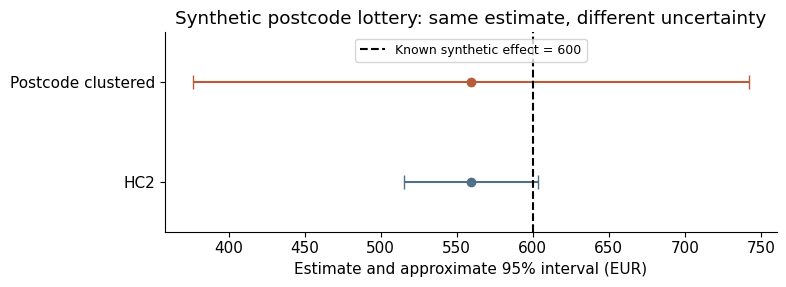

In [8]:
fig, ax = plt.subplots(figsize=(8, 3))
for row, (name, result) in enumerate(synthetic_results.iterrows()):
    ax.errorbar(result["Estimate"], row,
                xerr=[[result["Estimate"] - result["95% lower"]],
                      [result["95% upper"] - result["Estimate"]]],
                fmt="o", capsize=5, color=[BLUE, ORANGE][row])
ax.axvline(600, color="black", linestyle="--", label="Known synthetic effect = 600")
ax.set(yticks=[0, 1], yticklabels=synthetic_results.index,
       xlabel="Estimate and approximate 95% interval (EUR)",
       title="Synthetic postcode lottery: same estimate, different uncertainty",
       ylim=(-0.5, 1.5))
ax.legend(loc="upper center", fontsize=9)
fig.tight_layout()
plt.show()

### Exercise 5: change the design
Why need the estimate not equal 600? Why is sampling `winning_codes` from the unique `postcodes` array important? Would HC2 become sufficient just by interviewing more households in these same postcodes?

<details><summary>Answer</summary>

The treated and control postcodes can have different average baseline shocks by chance, so the realized estimate can differ from 600 despite unbiased assignment. Sampling without replacement from the household-level array can select the same postcode value more than once; with unequal sizes it also favors large postcodes. Sampling unique codes implements the stated draw. More households in the same postcodes do not create more independently varying postcode shocks or more assignment units, so HC2 still misses within-postcode dependence.

Clustered SEs need not always be larger than HC2 SEs, although they are larger here. The fixed number of winners also creates dependence among assignments; the displayed cluster interval is a conventional large-cluster approximation, not an exact randomization interval.

</details>

# Midterm review




## Part I. True or false

### Review 1. Density versus probability

Let $X$ be uniform on $[0,1/4]$. Its density is 4 on that interval. **True or false:** this is a valid density even though its value exceeds 1.

<details><summary>Show solution 1</summary>

**True.** A density must be nonnegative and integrate to 1; its height need not be at most 1. Here $\int_0^{1/4}4\,dx=1$. For example, $P(0\le X\le0.05)=4(0.05)=0.20$, whereas $P(X=0.05)=0$. Probabilities are areas under the density, not its pointwise values.

</details>

### Review 2. Uncorrelated variables

**True or false:** if $\operatorname{Cov}(X,Y)=0$, learning $X$ cannot give information about $Y$.

<details><summary>Show solution 2</summary>

**False.** Zero covariance rules out a particular linear association, not all dependence. For $X\sim\operatorname{Uniform}[-1,1]$ and $Y=X^2$,

$$\operatorname{Cov}(X,Y)=\mathbb E[X^3]-\mathbb E[X]\mathbb E[X^2]=0,$$

by symmetry. Yet $Y$ is completely determined once $X$ is known.

</details>

### Review 4. Noisy measurements

We observe iid measurements $W_i=X_i+e_i$, where $\mathbb E[X_i]=\mu$ and $\mathbb E[e_i]=0$. All expectations are finite. **True or false:** the sample mean $\bar W$ is unbiased for $\mu$.

<details><summary>Show solution 4</summary>

**True.** By linearity,

$$\mathbb E[\bar W]=\frac1n\sum_{i=1}^n\{\mathbb E[X_i]+\mathbb E[e_i]\}=\mu.$$

Zero-mean additive noise does not bias this mean estimator. Independence of $X_i$ and $e_i$ is not needed for this expectation calculation. Measurement error can increase uncertainty, and its consequences for a regression slope are a different question.

</details>

### Review 5. What a p-value conditions on

A two-sided test reports $p=0.12$. **True or false:** this means there is a 12% probability that the null hypothesis is true.

<details><summary>Show solution 5</summary>

**False.** Under the null hypothesis and the test's sampling assumptions, the p-value is the probability of a test statistic at least as extreme as the one observed, using the test's definition of extremeness. It is not $P(H_0\mid\text{data})$. At a prechosen 5% significance level, $p=0.12$ means we do not reject $H_0$; it does not establish $H_0$.

</details>

### Review 6. Confidence intervals

A valid frequentist procedure produces a 95% confidence interval for a population mean. **True or false:** 95% of observations in the population must lie inside that interval.

<details><summary>Show solution 6</summary>

**False.** The interval concerns the **population mean**, not the distribution of individual observations. Under repeated sampling, 95% of intervals from an exact 95% procedure contain the fixed population mean. An approximate procedure has approximate coverage under its assumptions. A prediction interval for individual outcomes answers a different question.

</details>

### Review 7. Heterogeneous effects under random assignment

Suppose $S\perp(Y(0),Y(1))$ and $0<P(S=1)<1$. **True or false:** population ATE, ATT, and ATU are equal even if individual treatment effects vary.

<details><summary>Show solution 7</summary>

**True.** Independence also holds between $S$ and the function $\Delta=Y(1)-Y(0)$. Hence

$$\mathbb E[\Delta\mid S=1]=\mathbb E[\Delta\mid S=0]=\mathbb E[\Delta].$$

Equality of these population averages does not require constant individual effects. Realized finite-group average effects can differ by chance. Conversely, equal ATE, ATT, and ATU alone do not prove random assignment: constant effects give equality even with confounding.

</details>

## Part II. Long-response questions

Show your steps and explain the assumptions. The displayed solutions include the reasoning, not just the final number.

### Review 9. Variance of a weighted difference

Let $X,Y$ have finite second moments and let $a,b,c$ be constants.

1. Starting from the definition of variance, derive $\operatorname{Var}(aX+bY+c)$ in terms of the variances and covariance of $X,Y$. Justify the expectation steps.
2. Compute $\operatorname{Var}(3X-2Y+5)$ when $\operatorname{Var}(X)=4$, $\operatorname{Var}(Y)=9$, and $\operatorname{Cov}(X,Y)=3$.
3. Would assuming independence change the answer? Why does the constant 5 not matter?

<details><summary>Show solution 9</summary>

**1. Center, expand, and take expectations.** Let $\mu_X=\mathbb E[X]$ and $\mu_Y=\mathbb E[Y]$. Linearity of expectation gives $\mathbb E[aX+bY+c]=a\mu_X+b\mu_Y+c$. Thus

$$\begin{aligned}
\operatorname{Var}(aX+bY+c)
&=\mathbb E\!\left[(a(X-\mu_X)+b(Y-\mu_Y))^2\right]\\
&=a^2\mathbb E[(X-\mu_X)^2]+b^2\mathbb E[(Y-\mu_Y)^2]\\
&\quad+2ab\mathbb E[(X-\mu_X)(Y-\mu_Y)]\\
&=a^2\operatorname{Var}(X)+b^2\operatorname{Var}(Y)+2ab\operatorname{Cov}(X,Y).
\end{aligned}$$

The second equality uses expansion and linearity; the final equality uses the definitions of variance and covariance. Independence was not assumed.

**2. Substitute the values:** $9(4)+4(9)-12(3)=36$.

**3.** Independence would force covariance to be zero, so it is incompatible with the supplied covariance of 3. In a different model with the same marginal variances but independence, the result would be 72. A constant shifts both the variable and its mean equally, leaving centered deviations unchanged. The negative coefficient on $Y$ makes positive covariance reduce the variance of this difference.

</details>

### Review 11. Heterogeneous effects and the target population

A university evaluates a new study workshop. Let $S=1$ mean attending it, $Y(s)$ be the potential exam score, and $B=1$ indicate a beginner **before** the workshop. Define $\Delta=Y(1)-Y(0)$.

Suppose $\mathbb E[\Delta\mid B=1]=6$ points and $\mathbb E[\Delta\mid B=0]=-4$ points. Beginners make up 70% of the university's target population.

1. Use the LIE to express the population ATE as a weighted average of the two subgroup effects. Calculate it.
2. What beginner share would make the ATE exactly zero?
3. A second university has 30% beginners. Assuming both subgroup effects carry over unchanged, what is its ATE?
4. Does the LIE decomposition itself require random assignment?

<details><summary>Show solution 11</summary>

**1.** Apply the LIE to the **treatment effect**, keeping the same person's two potential outcomes inside the difference:

$$\begin{aligned}
\tau=\mathbb E[\Delta]
&=\mathbb E_B[\mathbb E[\Delta\mid B]]\\
&=6P(B=1)-4P(B=0).
\end{aligned}$$

At beginner share 0.7, $\tau=0.7(6)+0.3(-4)=3$ points. Positive average effects can coexist with harmful effects for a subgroup.

**2.** For beginner share $q$, $\tau(q)=6q-4(1-q)=10q-4$. It is zero at $q=0.4$; positive above that share and negative below it.

**3.** At $q=0.3$, $\tau=-1$ point.

**4.** The LIE is a probability identity and does not need random assignment.

</details>

### Review 12. When a descriptive slope understates an effect

Suppose the structural model is

$$Y=10+2X-3Z+\eta,$$

where changing $X$ leaves $Z$ and $\eta$ fixed, and $\eta$ is independent of $X$. All second moments are finite, $\operatorname{Var}(X)=2$, and $\operatorname{Cov}(X,Z)=1$. A researcher fits a descriptive regression of $Y$ on an intercept and $X$ alone.

1. Derive the population slope $\beta_1=\operatorname{Cov}(X,Y)/\operatorname{Var}(X)$.
2. Compare it with the causal effect of a one-unit increase in $X$.
3. Holding $\operatorname{Var}(X)=2$, how large would $\operatorname{Cov}(X,Z)$ have to be for the descriptive slope to be negative? Assume the other moments permit that covariance.
4. Would a very large sample or a small regression p-value resolve the causal problem?

<details><summary>Show solution 12</summary>

**1.** Use covariance linearity, the fact that a constant has zero covariance with $X$, and $\operatorname{Cov}(X,\eta)=0$:

$$\begin{aligned}
\beta_1
&=\frac{\operatorname{Cov}(X,10+2X-3Z+\eta)}{\operatorname{Var}(X)}\\
&=\frac{2\operatorname{Var}(X)-3\operatorname{Cov}(X,Z)+0}{\operatorname{Var}(X)}\\
&=2-3\frac{\operatorname{Cov}(X,Z)}{\operatorname{Var}(X)}=2-\frac32=0.5.
\end{aligned}$$

**2.** The structural effect is 2. The descriptive slope is smaller by 1.5 because larger $X$ is associated with larger $Z$, which lowers $Y$. The sign of confounding depends on both the association with the omitted variable and that variable's outcome effect.

**3.** The slope is negative when $2-3\operatorname{Cov}(X,Z)/2<0$, or $\operatorname{Cov}(X,Z)>4/3$. At equality the descriptive slope is zero even though the causal effect is positive.

**4.** No. Under suitable sampling conditions, more observations can make the fitted slope converge to the descriptive slope of 0.5. A small p-value can provide evidence that this descriptive slope is nonzero; it does not remove confounding or change the causal effect to 0.5.

</details>

## Part III. Diagnostic questions

Read the assignment mechanism and the tables together. Identify the main problem, explain its consequence, and propose a concrete improvement. All reported numbers are hypothetical.

### Review 14. Quiet-hours coaching in shared residence halls

A university wants the effect on sleep of providing quiet-hours coaching to **every resident**, compared with providing it to nobody. It individually randomizes 240 residents from 24 shared halls into two groups of 120. All assigned residents receive the coaching; no control resident receives it. Coached residents may lower their voices and turn down music, changing the noise heard by their untreated neighbors. All residents provide follow-up data.

**Pretreatment balance:**

| Characteristic | Assigned coaching: mean (SD) | Control: mean (SD) | Difference | Reported p-value |
|---|---:|---:|---:|---:|
| Age, years | 20.20 (1.20) | 20.30 (1.30) | −0.10 | 0.54 |
| Baseline sleep, hours/night | 6.80 (1.00) | 6.75 (1.00) | 0.05 | 0.70 |
| Residents | 120 | 120 | | |

**Follow-up outcome:**

| Outcome | Assigned coaching: mean (SD) | Control: mean (SD) | Difference (SE) | Reported p-value |
|---|---:|---:|---:|---:|
| Sleep, hours/night | 7.10 (1.20) | 7.00 (1.20) | 0.10 (0.155) | 0.52 |

The analyst calculated **all reported SEs and p-values using independent-person, large-sample normal formulas**, ignoring halls. The rounded entries come from those formulas.

The housing office concludes: “Balance proves the experiment's assumptions. The p-value means a 52% chance of no effect, and we can rule out a benefit of 0.3 hours per night. Offering coaching to everyone would therefore not improve sleep.”

1. What is the main identification problem for the university's stated all-versus-none policy question? Explain a mechanism, not just an acronym.
2. What do the balance table and the nonsignificant outcome comparison establish, and what do they not establish?
3. Using the reported SE provisionally, calculate a nominal 95% interval. Can even this interval rule out a benefit of 0.3 hours?
4. Propose a design and an inference method that better match the policy question. Would changing the standard errors alone solve everything?

<details><summary>Show solution 14</summary>

**1. SUTVA.** A resident's sleep can depend on whether nearby residents were coached. The relevant potential outcome may be $Y_i(s_i,\mathbf s_{-i})$, not just $Y_i(s_i)$. Untreated residents can benefit from quieter treated neighbors. The individual comparison under a mixed assignment does not directly identify the effect of coaching everyone versus nobody. Spillovers might shrink that comparison in this story, but neither their sign nor the policy effect's magnitude is established by the table. Randomization can still support design-specific contrasts; it does not make all policy contrasts identical.

**2.** The observed pretreatment means are similar. That is a useful diagnostic, not proof of all assumptions, and the nominal balance tests themselves ignore halls. Balance cannot establish absence of interference. The reported outcome p-value is not the probability of no effect. Even with valid inference, failure to reject zero would not prove a zero or negligible effect; here shared hall shocks can also invalidate the independent-person uncertainty calculation.

**3.** Treating the displayed SE as if valid,

$$0.10\pm1.96(0.155)\approx[-0.204,\ 0.404]\text{ hours/night}.$$

This interval includes both zero and 0.3, so even the analyst's own calculation does not rule out a 0.3-hour benefit. Because the sampling dependence was ignored, this is only a **nominal** interval. It also addresses the mixed-design comparison, not automatically the full-policy effect.

**4.** Randomize many entire residence halls to coaching for everyone or coaching for nobody, keeping halls sufficiently separate to make cross-hall spillovers implausible. Define the target as the resulting hall-wide policy and analyze hall means or use inference accounting for hall clustering and the assignment design. Prespecify how residents versus halls are weighted if hall sizes differ. The number of halls matters for precision. Clustered SEs alone address dependence in uncertainty calculations; they do not change the exposure contrast or eliminate interference.

```python
from scipy import stats
sleep_se = (1.2**2 / 120 + 1.2**2 / 120) ** 0.5
print("Nominal SE:", sleep_se)
print("Nominal two-sided p:", 2 * stats.norm.sf(abs(0.10 / sleep_se)))
print("Nominal interval:", (0.10 - 1.96 * sleep_se, 0.10 + 1.96 * sleep_se))
```

</details>

### Review 15. A transit-pass lottery with incomplete take-up

An outside agency uses a lottery to offer free transit passes to 200 of 400 eligible job seekers. Researchers observe the lottery and subsequent employment. Let $Z$ denote a pass offer, $S$ actual pass use, and $Y$ employment after six months. Some offered applicants decline; some applicants without an offer obtain equivalent passes elsewhere. Assignment is random, employment is observed for everyone, and there are no spillovers between applicants.

| Quantity | Offered, $Z=1$ | Not offered, $Z=0$ |
|---|---:|---:|
| Applicants | 200 | 200 |
| Actually use a pass | 140 | 20 |
| Employed after six months | 144 | 128 |

1. Calculate the employment difference by **offer** and state the causal parameter it estimates. Give the units.
2. A researcher says, “Because not everyone complied, the lottery tells us nothing causal.” Assess this claim.
3. Another researcher discards the offer indicator and compares actual pass users with nonusers. Does the lottery automatically justify that comparison? Explain.
4. Does the offer effect automatically generalize to all unemployed adults? What information is missing if we want an effect of actually using a pass?

<details><summary>Show solution 15</summary>

**1.** The employment rates are $144/200=0.72$ and $128/200=0.64$. Their difference is **0.08, or 8 percentage points**. Under the stated assumptions and consistency, this estimates an **intention-to-treat (ITT)** effect of the offer among the eligible lottery population:

$$\tau_{\mathrm{offer}}=\mathbb E[Y^{Z}(1)-Y^{Z}(0)],$$

where $Y^{Z}(z)$ is employment under offer assignment $z$, allowing pass use to respond to that offer. The 8-point realized estimate need not equal the population effect exactly. A conclusion about statistical significance would require a justified uncertainty calculation.

**2.** False. Incomplete take-up prevents us from equating the offer effect with a use effect, but it does not destroy randomized assignment of the offer. The ITT remains a causal question.

**3.** No. Actual use is not randomized: willingness or ability to use a pass may be related to employment prospects. Reclassifying or selecting people by post-assignment use loses the original randomized comparison. Moreover, this table does not cross-tabulate employment by actual use, so even the descriptive users/nonusers outcome difference cannot be computed from it.

**4.** Eligibility, application, and the local setting restrict the target population. Generalization needs additional evidence. The use rates are 70% and 10%, but those rates alone do not identify an overall ATE of use. Linking the randomized offer to a use effect requires additional assumptions and methods beyond this review; do not silently relabel or rescale the ITT as that ATE.

</details>

---
## Sources and attribution

- **Research:** Kuhn, P., Kooreman, P., Soetevent, A., and Kapteyn, A. (2011). [The Effects of Lottery Prizes on Winners and Their Neighbors: Evidence from the Dutch Postcode Lottery](https://www.aeaweb.org/articles?id=10.1257/aer.101.5.2226). *American Economic Review*, 101(5), 2226–2247.
- **Data provenance:** The paper's [replication archive, DOI 10.3886/E116096V1](https://www.openicpsr.org/openicpsr/project/116096/version/V1/view), provides the research provenance; this notebook does not claim that the local course file or its unrestricted regression reproduces a published analysis.
